In [211]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_ta as ta

%load_ext autoreload
%autoreload 2

from Engine.DataTimeseries import DataTimeseries
from Engine.Backtester import Backtester
from Engine.Utils import timeframe_to_minutes
from Graphics.Chart import Chart

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [240]:
data = DataTimeseries('./Data/nq_continous.csv')
data.convert_timezone('America/New_York')
data.resample_data('1H')
print(data.get_ohlc_prices_series())
data.slice(start_date=pd.Timestamp(year=2018, month=1, day=1))
in_sample, out_of_sample = data.split(pd.Timestamp(year=2023, month=1, day=1))

df: pd.DataFrame = in_sample.get_ohlc_prices_series()




Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows



/Users/newuser/Desktop/Random Coding Crap/Futures/RugbeatunosBacktestingSuite/Engine/DataTimeseries.py:5: FutureWarning:

'H' is deprecated and will be removed in a future version, please use 'h' instead.



                               Open      High       Low     Close
Time                                                             
2010-06-06 21:00:00-04:00   1826.25   1827.50   1811.50   1815.75
2010-06-06 22:00:00-04:00   1816.00   1818.00   1811.75   1813.00
2010-06-06 23:00:00-04:00   1813.00   1821.75   1812.50   1819.75
2010-06-07 00:00:00-04:00   1819.00   1822.50   1815.75   1820.50
2010-06-07 01:00:00-04:00   1820.25   1823.25   1818.75   1823.25
...                             ...       ...       ...       ...
2025-11-21 14:00:00-05:00  24350.50  24559.50  24203.50  24477.25
2025-11-21 15:00:00-05:00  24477.50  24596.25  24427.50  24458.75
2025-11-21 16:00:00-05:00  24458.75  24496.25  24285.00  24313.75
2025-11-21 17:00:00-05:00  24312.75  24358.25  24302.75  24349.00
2025-11-23 19:00:00-05:00  24455.75  24555.25  24455.25  24471.50

[92142 rows x 4 columns]


In [241]:

def generate_trend_filter(ema_length):
    ema = ta.ema(df['Close'], length=ema_length)
    ema_dx = ema.diff().fillna(0)
    return np.where(ema_dx > 0, 1, -1)

trend_filter = generate_trend_filter(768)

def generate_signal(slow_length, fast_length):
    ema_slow = ta.ema(df['Close'], length=slow_length)
    ema_fast = ta.ema(df['Close'], length=fast_length)
    ewmac_sign = np.sign(ema_fast - ema_slow)

    return np.where(ewmac_sign == trend_filter, trend_filter, 0)

print(pd.Series(trend_filter).value_counts())
signal = generate_signal(128, 8)
print(pd.Series(signal).value_counts())


 1    18595
-1    10974
Name: count, dtype: int64
 1    14713
-1     7790
 0     7066
Name: count, dtype: int64


In [216]:
chart = Chart(in_sample.get_ohlc_prices(), in_sample.get_indicies())
chart.add_ema(256, color='yellow')
# chart.add_ema(128, color='silver')
# chart.add_ema(8, color='blue')
chart.show()

In [ ]:
ema = ta.ema(df['Close'], length=200)
dist_long = np.where(df['Close'] > ema, df['Close'] - ema)



301 118700.0


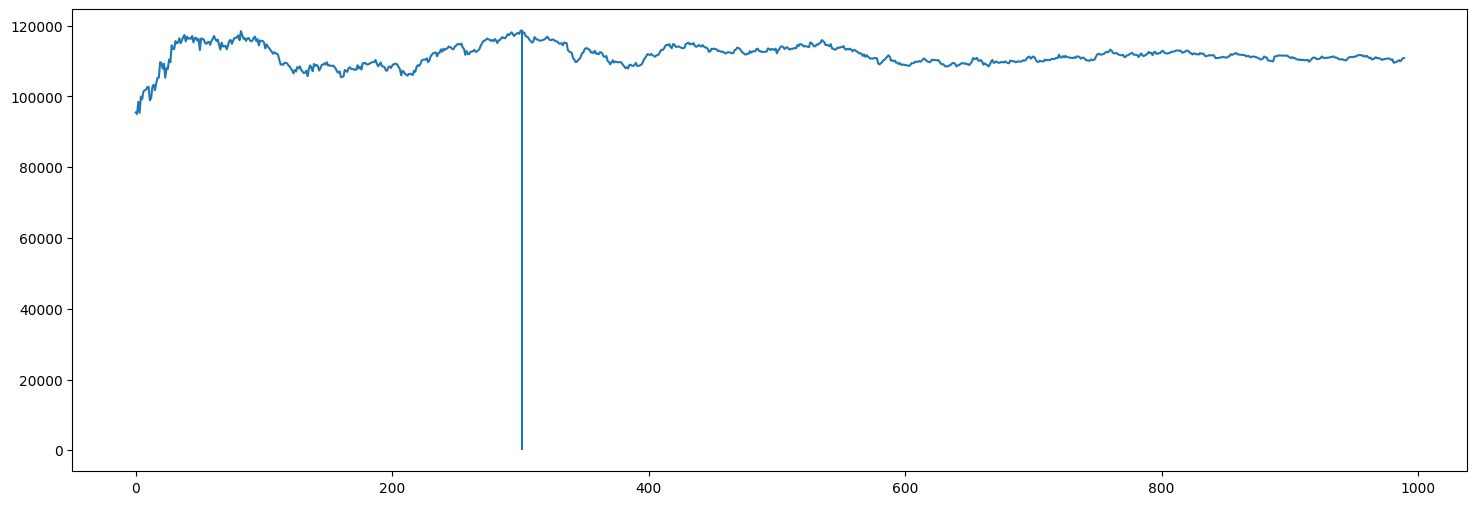

In [242]:
final_equities = []
ema_lengths = np.arange(10, 1000)

for i in ema_lengths:
    # signal = generate_trend_filter(i)
    bt = Backtester(
        ohlc=in_sample.get_ohlc_prices(),
        indicies=in_sample.get_indicies(),
        signal=generate_trend_filter(i),
        timeframe=in_sample.get_timeframe(),
        tick_value=0.5,
        contract_multiplier=2.0,
        initial_equity=100_000,
        slippage_ticks=2,
        commission=0.5
    )

    bt.quick_backtest()
    final_equities.append(bt.final_equity)

print()
print(np.argmax(final_equities), np.max(final_equities))
plt.figure(figsize=(18,6))
plt.plot(final_equities)
plt.vlines(np.argmax(final_equities), ymin=0, ymax=np.max(final_equities))
plt.show()


301 118642.0


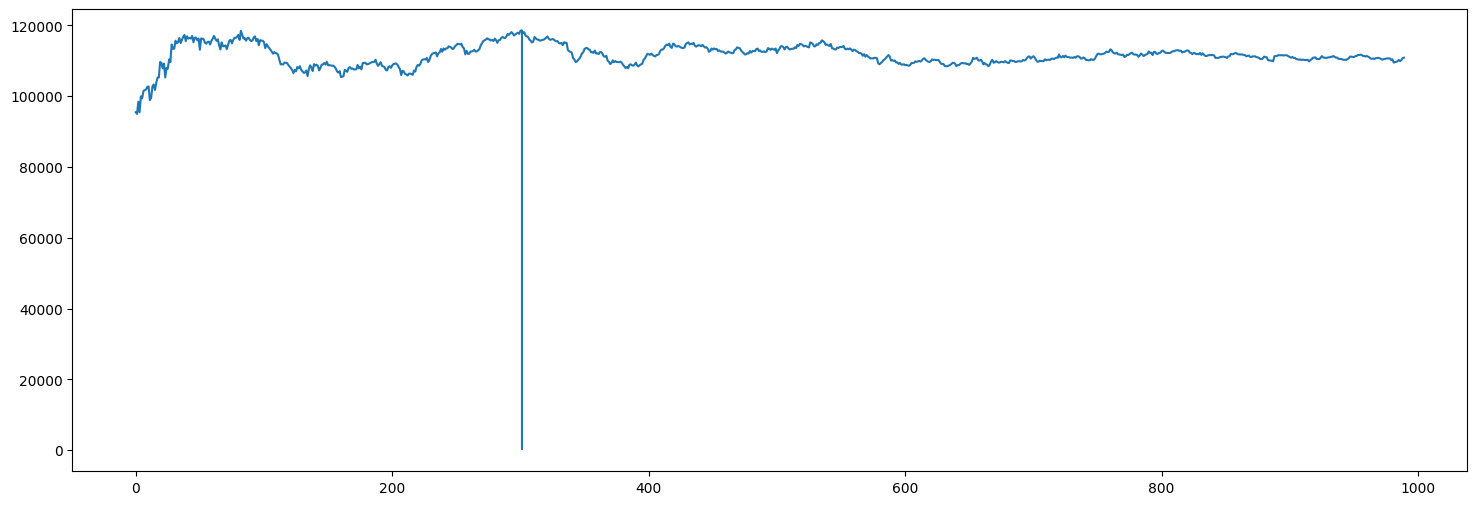

In [243]:
final_equities = []
ema_lengths = np.arange(10, 1000)

for i in ema_lengths:
    ema = ta.ema(df['Close'], length=i)
    signal = np.where(df['Close'] > ema, 1, -1)
    bt = Backtester(
        ohlc=in_sample.get_ohlc_prices(),
        indicies=in_sample.get_indicies(),
        signal=signal,
        timeframe=in_sample.get_timeframe(),
        tick_value=0.5,
        contract_multiplier=2.0,
        initial_equity=100_000,
        slippage_ticks=2,
        commission=0.5
    )

    bt.quick_backtest()
    final_equities.append(bt.final_equity)

print()
print(np.argmax(final_equities), np.max(final_equities))
plt.figure(figsize=(18,6))
plt.plot(final_equities)
plt.vlines(np.argmax(final_equities), ymin=0, ymax=np.max(final_equities))
plt.show()


        Backtest Results from 2018-01-01 19:00:00-05:00 to 2022-12-30 17:00:00-05:00 (1823 days 22:00:00)
        Equity:     $100,000.00 -> $115,944.75
        Buy & Hold: $100,000.00 -> $172,070.28
        Buy & Hold Return (%): 72.07%
        Strategy Return (%):   15.94%

        Total Trades:     1394.00
        Win Rate:         26.97%
        95% CI:           24.71% - 29.36%
        Avg. Win:         $287.34
        Avg. Loss:        $-90.47
        Ratio Win/Loss:   3.18
        Expected Value:   $11.44

        Largest Win:      $3,303.75
        Largest Loss:     $-1,137.75
        Max Consec. Wins: 27
        Max Consec. Loss: 27

        Max Drawdown from 2022-02-02 08:00:00-05:00 to 2022-02-17 09:00:00-05:00 (15 days 01:00:00)
        Max Drawdown:     $-3,888.25
        Max Drawdown (%): -3.29%

        Slippage:   2 ticks
        Commission: $0.25
        Contract Multiplier: $2.00
        Transaction Costs:   $1,741.25

        CAGR:              3.01%
        Sharpe 

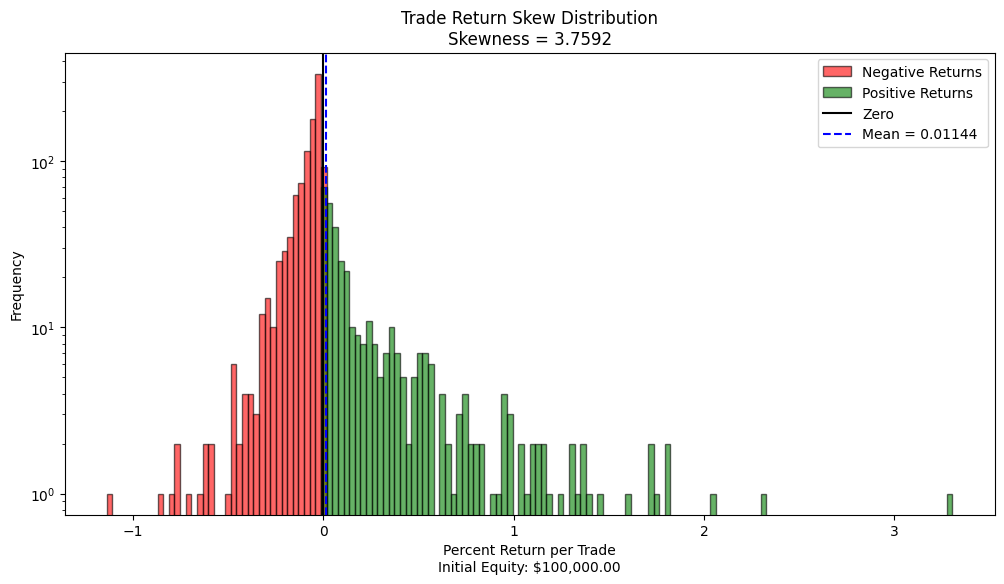

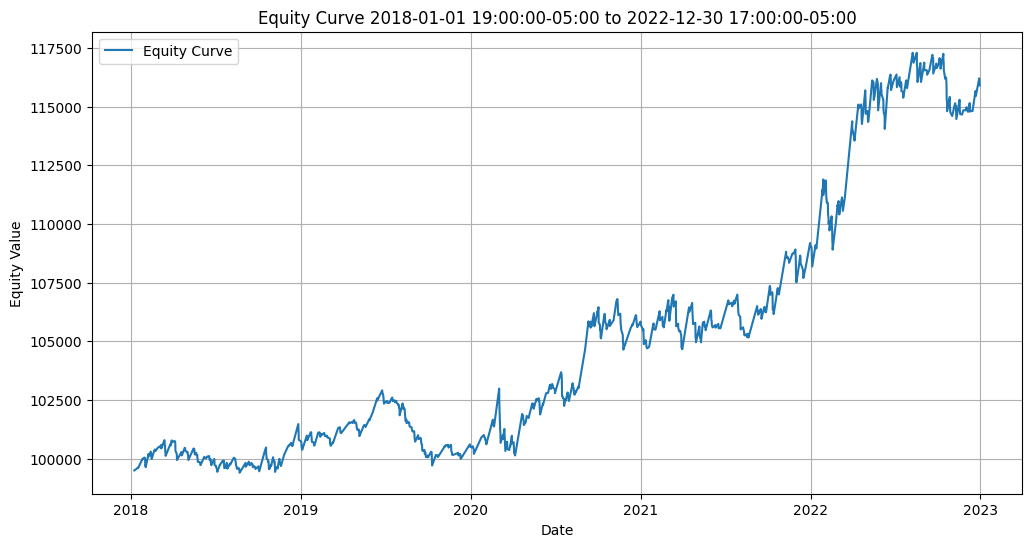

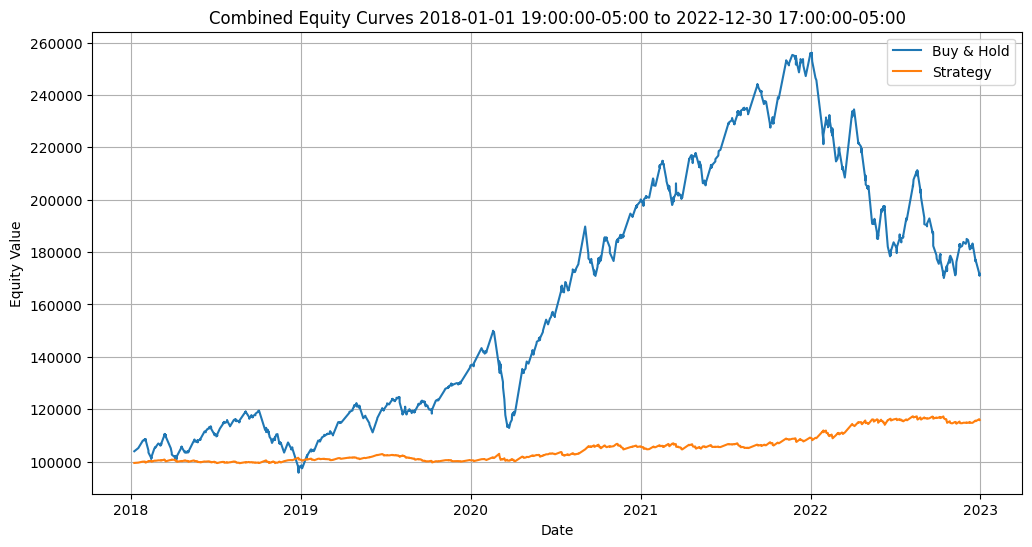

In [245]:
from Engine.EquityCurve import EquityCurve

ema = ta.ema(df['Close'], length=100)
signal = np.where(df['Close'] > ema, 1, -1)
bt = Backtester(
        ohlc=in_sample.get_ohlc_prices(),
        indicies=in_sample.get_indicies(),
        signal=signal,
        timeframe=in_sample.get_timeframe(),
        tick_value=.5,
        contract_multiplier=2,
        initial_equity=100_000,
        slippage_ticks=2,
        commission=0.25
    )
bt.full_backtest()
print(bt)

bh_curve = bt.generate_buy_hold_equity_curve()
bt.generate_skew_curve().plot()
strategy_curve = bt.generate_equity_curve()
strategy_curve.plot()
EquityCurve.combine_equity_curves([bh_curve, strategy_curve], ['Buy & Hold', 'Strategy'])
# bt.monte_carlo_permutation_test(1000, 0.1)